# Sprint 3 (extensión) — MegaMarket: ¿qué pasa con el portafolio óptimo si un competidor reacciona?

Jacobo Argote, Andrés Cardona, Miguel Valencia y Juan José Gil

##**CÓDIGO GENERADO CON CLAUDE**

## De dónde venimos y qué agregamos

El algoritmo genético del Sprint 3 escogió el portafolio que más utilidad esperada deja con 70.000.000 de presupuesto y 25 posiciones de bodega: **Higo Deshidratado, Jugo Natural y Café Molido**, con $122.000.000 de utilidad anual. La fuerza bruta mostró que hay otro portafolio empatado (Mix de Frutos Secos, Barra Energética y Jugo Natural).

**Lo que ese resultado supone:** que ningún competidor reacciona. La utilidad esperada de cada producto es un número fijo.

**Lo que agrega este notebook:** un competidor que puede **entrar con un producto parecido** al nuestro y quitarnos parte de las ventas. Eso es un juego, y se resuelve con dos herramientas que hacen trabajos distintos:

| Herramienta | Qué hace | Dónde se usa aquí |
|---|---|---|
| **Teoría de juegos (matriz de pagos, Nash, Minimax)** | **Evalúa** una decisión cuando el rival reacciona | Califica cada portafolio por lo que nos queda en el peor caso |
| **Algoritmo genético** | **Busca** entre las 256 combinaciones | Propone portafolios y usa esa calificación como *fitness* |

> **Nota:** igual que en el Sprint 3, los costos, espacios y utilidades son ficticios. La **erosión** (qué porcentaje de la utilidad nos quita el rival si entra en un producto) y los pagos del rival son **supuestos ilustrativos**. El objetivo es mostrar la lógica, no representar cifras reales de MegaMarket.

## Parte 0 — Candidatos, restricciones y el supuesto de erosión

Los 8 candidatos y las restricciones son los mismos del Sprint 3. Se agrega un dato por producto:

- **erosión:** fracción de la utilidad esperada que perdemos si un competidor entra con un producto parecido. Un producto más fácil de copiar (por ejemplo el Jugo) tiene erosión alta. Uno más difícil de imitar (por ejemplo la Compota) la tiene baja.

In [1]:
# =============================================================================
# 1. CANDIDATOS, RESTRICCIONES Y EROSIÓN
# =============================================================================
import random, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CANDIDATOS = {
    "Higo Deshidratado Riovalle":     {"costo_lanzamiento": 18_000_000, "espacio_bodega": 6,  "utilidad_esperada_anual": 32_000_000},
    "Mix de Frutos Secos Riovalle":   {"costo_lanzamiento": 25_000_000, "espacio_bodega": 8,  "utilidad_esperada_anual": 48_000_000},
    "Barra Energética Riovalle":      {"costo_lanzamiento": 15_000_000, "espacio_bodega": 4,  "utilidad_esperada_anual": 22_000_000},
    "Granola Riovalle":               {"costo_lanzamiento": 20_000_000, "espacio_bodega": 7,  "utilidad_esperada_anual": 30_000_000},
    "Jugo Natural Riovalle":          {"costo_lanzamiento": 30_000_000, "espacio_bodega": 10, "utilidad_esperada_anual": 52_000_000},
    "Snack de Plátano Riovalle":      {"costo_lanzamiento": 12_000_000, "espacio_bodega": 5,  "utilidad_esperada_anual": 17_000_000},
    "Compota Riovalle":               {"costo_lanzamiento": 10_000_000, "espacio_bodega": 3,  "utilidad_esperada_anual": 14_000_000},
    "Café Molido Riovalle":           {"costo_lanzamiento": 22_000_000, "espacio_bodega": 6,  "utilidad_esperada_anual": 38_000_000},
}

NOMBRES = list(CANDIDATOS.keys())          # el orden define la posición de cada gen
N_GENES = len(NOMBRES)

PRESUPUESTO_TOTAL = 70_000_000
ESPACIO_BODEGA_TOTAL = 25

# SUPUESTO ILUSTRATIVO: fracción de la utilidad que se pierde si el rival entra en ese producto
EROSION = {
    "Higo Deshidratado Riovalle":   0.30,
    "Mix de Frutos Secos Riovalle": 0.50,
    "Barra Energética Riovalle":    0.40,
    "Granola Riovalle":             0.40,
    "Jugo Natural Riovalle":        0.60,
    "Snack de Plátano Riovalle":    0.30,
    "Compota Riovalle":             0.20,
    "Café Molido Riovalle":         0.50,
}

# SUPUESTO ILUSTRATIVO: cuántos productos puede atacar el rival a la vez (recursos limitados)
K_ATAQUES = 1

corto = lambda n: n.replace(" Riovalle", "")
print(f"{N_GENES} candidatos viables | presupuesto ${PRESUPUESTO_TOTAL:,.0f} | espacio {ESPACIO_BODEGA_TOTAL} posiciones | el rival ataca {K_ATAQUES} producto(s)")

8 candidatos viables | presupuesto $70,000,000 | espacio 25 posiciones | el rival ataca 1 producto(s)


## Parte 1 — El juego de un solo producto

Antes de mirar el portafolio completo, se modela **un producto** (el Jugo Natural, que aporta 43% de la utilidad y consume 43% del presupuesto).

| Elemento | Definición |
|---|---|
| **Jugadores** | Riovalle y un competidor de la categoría |
| **Estrategias** | Riovalle: Lanzar / No lanzar. Rival: Entrar / No entrar |
| **Pago de Riovalle** | Utilidad neta del primer año: `utilidad × (1 − erosión) − costo` si el rival entra, `utilidad − costo` si no entra, y 0 si no lanza |
| **Pago del rival** | Supuesto ilustrativo (ver abajo) |
| **Tipo** | No cooperativo, suma no cero, **secuencial** (Riovalle lanza y el rival responde) |

**Dos ideas útiles antes de la matriz:**

1. **Erosión de equilibrio:** `1 − costo/utilidad`. Es el porcentaje de utilidad que el rival nos puede quitar antes de que lanzar deje de pagarse en el primer año.
2. **Inducción hacia atrás:** en un juego secuencial se resuelve de abajo hacia arriba, igual que Minimax. Para cada jugada de Riovalle se mira qué respondería el rival, y Riovalle escoge la jugada que mejor le va *sabiendo eso*.

In [2]:
# =============================================================================
# 2. EROSIÓN DE EQUILIBRIO — hasta dónde aguanta cada producto
# =============================================================================
def erosion_de_equilibrio(nombre):
    c = CANDIDATOS[nombre]
    return 1 - c["costo_lanzamiento"] / c["utilidad_esperada_anual"]

filas = [{"Producto": corto(n),
          "Utilidad": c["utilidad_esperada_anual"],
          "Costo": c["costo_lanzamiento"],
          "Utilidad neta": c["utilidad_esperada_anual"] - c["costo_lanzamiento"],
          "Erosión de equilibrio": erosion_de_equilibrio(n),
          "Erosión supuesta": EROSION[n]}
         for n, c in CANDIDATOS.items()]
tabla_eq = pd.DataFrame(filas)
display(tabla_eq.style.format({"Utilidad": "${:,.0f}", "Costo": "${:,.0f}", "Utilidad neta": "${:,.0f}",
                               "Erosión de equilibrio": "{:.1%}", "Erosión supuesta": "{:.0%}"}).hide(axis="index"))
print("Si la erosión supuesta supera la de equilibrio, el producto pierde dinero en el primer año.")

Producto,Utilidad,Costo,Utilidad neta,Erosión de equilibrio,Erosión supuesta
Higo Deshidratado,"$32,000,000","$18,000,000","$14,000,000",43.8%,30%
Mix de Frutos Secos,"$48,000,000","$25,000,000","$23,000,000",47.9%,50%
Barra Energética,"$22,000,000","$15,000,000","$7,000,000",31.8%,40%
Granola,"$30,000,000","$20,000,000","$10,000,000",33.3%,40%
Jugo Natural,"$52,000,000","$30,000,000","$22,000,000",42.3%,60%
Snack de Plátano,"$17,000,000","$12,000,000","$5,000,000",29.4%,30%
Compota,"$14,000,000","$10,000,000","$4,000,000",28.6%,20%
Café Molido,"$38,000,000","$22,000,000","$16,000,000",42.1%,50%


Si la erosión supuesta supera la de equilibrio, el producto pierde dinero en el primer año.


In [3]:
# =============================================================================
# 3. MATRIZ DE PAGOS 2x2, NASH E INDUCCIÓN HACIA ATRÁS
# =============================================================================
def matriz_producto(nombre, erosion, rival_entra_vs_lanza, rival_entra_vs_no_lanza):
    """Filas: Riovalle (Lanzar, No lanzar). Columnas: Rival (Entrar, No entrar). Pagos en COP."""
    c = CANDIDATOS[nombre]
    u, costo = c["utilidad_esperada_anual"], c["costo_lanzamiento"]
    A = np.array([[u * (1 - erosion) - costo, u - costo],     # pago de Riovalle
                  [0.0,                       0.0]])
    B = np.array([[rival_entra_vs_lanza,      0.0],            # pago del rival
                  [rival_entra_vs_no_lanza,   0.0]])
    return A, B


def nash_puro(A, B):
    """Celdas donde ninguno mejora cambiando solo (el subrayado de la clase)."""
    nash = []
    for i in range(2):
        for j in range(2):
            if A[i, j] >= A[:, j].max() - 1e-9 and B[i, j] >= B[i, :].max() - 1e-9:
        # ¿Es A[i,j] el máximo de su columna? (mejor respuesta de Riovalle)
        # ¿Es B[i,j] el máximo de su fila? (mejor respuesta del rival)
                nash.append((i, j))
    return nash


def solucion_secuencial(A, B):
    """Riovalle mueve primero; el rival responde con su mejor respuesta (inducción hacia atrás)."""
    respuesta = [int(np.argmax(B[i, :])) for i in range(2)]          # mejor respuesta del rival a cada jugada
    i = int(np.argmax([A[i, respuesta[i]] for i in range(2)]))        # Riovalle escoge sabiendo eso
    return i, respuesta[i]


FILAS, COLS = ["Lanzar", "No lanzar"], ["Entrar", "No entrar"]

def mostrar_caso(titulo, nombre, erosion, rival_entra_vs_lanza, rival_entra_vs_no_lanza):
    A, B = matriz_producto(nombre, erosion, rival_entra_vs_lanza, rival_entra_vs_no_lanza)
    nash = nash_puro(A, B)
    tabla = pd.DataFrame(
        [[f"({A[i,j]/1e6:.1f} ; {B[i,j]/1e6:.1f})" + (" ← Nash" if (i, j) in nash else "") for j in range(2)] for i in range(2)],
        index=[f"Riovalle: {f}" for f in FILAS], columns=[f"Rival: {c}" for c in COLS])
    print(f"\n=== {titulo} ===  (millones COP; cada celda = Riovalle ; Rival)")
    display(tabla)
    print("Equilibrios de Nash puros:", " y ".join(f"({FILAS[i]}, {COLS[j]})" for i, j in nash))
    i, j = solucion_secuencial(A, B)
    print(f"Si Riovalle mueve primero: ({FILAS[i]}, {COLS[j]}) -> Riovalle {A[i,j]/1e6:.1f}M, Rival {B[i,j]/1e6:.1f}M")


JUGO = "Jugo Natural Riovalle"
mostrar_caso("Caso A: el rival le quita 35% y entrar le conviene siempre", JUGO, 0.35, 6e6, 18e6)
mostrar_caso("Caso B: el rival le quita 50% y entrar le conviene siempre", JUGO, 0.50, 6e6, 18e6)
mostrar_caso("Caso C: el rival le quita 50% pero entrar contra un producto ya lanzado le da pérdida", JUGO, 0.50, -3e6, 18e6)


=== Caso A: el rival le quita 35% y entrar le conviene siempre ===  (millones COP; cada celda = Riovalle ; Rival)


,Rival: Entrar,Rival: No entrar
Riovalle: Lanzar,(3.8 ; 6.0) ← Nash,(22.0 ; 0.0)
Riovalle: No lanzar,(0.0 ; 18.0),(0.0 ; 0.0)


Equilibrios de Nash puros: (Lanzar, Entrar)
Si Riovalle mueve primero: (Lanzar, Entrar) -> Riovalle 3.8M, Rival 6.0M

=== Caso B: el rival le quita 50% y entrar le conviene siempre ===  (millones COP; cada celda = Riovalle ; Rival)


,Rival: Entrar,Rival: No entrar
Riovalle: Lanzar,(-4.0 ; 6.0),(22.0 ; 0.0)
Riovalle: No lanzar,(0.0 ; 18.0) ← Nash,(0.0 ; 0.0)


Equilibrios de Nash puros: (No lanzar, Entrar)
Si Riovalle mueve primero: (No lanzar, Entrar) -> Riovalle 0.0M, Rival 18.0M

=== Caso C: el rival le quita 50% pero entrar contra un producto ya lanzado le da pérdida ===  (millones COP; cada celda = Riovalle ; Rival)


,Rival: Entrar,Rival: No entrar
Riovalle: Lanzar,(-4.0 ; -3.0),(22.0 ; 0.0) ← Nash
Riovalle: No lanzar,(0.0 ; 18.0) ← Nash,(0.0 ; 0.0)


Equilibrios de Nash puros: (Lanzar, No entrar) y (No lanzar, Entrar)
Si Riovalle mueve primero: (Lanzar, No entrar) -> Riovalle 22.0M, Rival 0.0M


### Lectura de los tres casos

- **Caso A:** entrar es una estrategia dominante para el rival (6 > 0 y 18 > 0). Sabiendo eso, Riovalle compara lanzar con la entrada del rival contra no lanzar, y sigue lanzando. Los $22M de utilidad neta del Sprint 3 solo ocurrirían si el rival no existiera.
- **Caso B:** con 50% de erosión, lanzar contra un rival que entra da pérdida. A Riovalle le conviene **no lanzar** el Jugo, lo que libera presupuesto y bodega para otro producto.
- **Caso C:** hay **dos equilibrios** y no se sabe cuál ocurre si todos deciden a la vez. Como Riovalle mueve primero, **lanzar funciona como compromiso**: el rival observa que el producto ya existe y no entra. Llegar primero tiene valor porque cambia lo que le conviene al rival.

## Parte 2 — Minimax del portafolio completo

Un competidor real tiene recursos limitados, así que no entra en todos nuestros productos a la vez. Se modela como el Minimax de la clase, en su versión más simple (un solo movimiento del rival):

- **MAX (Riovalle):** escoge el portafolio.
- **MIN (el rival):** escoge el producto que más daño nos haga. Daño = `utilidad × erosión`.
- **Valor del portafolio en el peor caso** = utilidad esperada total − pérdida máxima que el rival puede causar.

El árbol de decisión es de solo dos niveles, por lo que no hace falta poda Alfa-Beta: basta calcular el máximo de las pérdidas.

In [4]:
# =============================================================================
# 4. FUNCIONES SOBRE UN PORTAFOLIO Y MINIMAX
# =============================================================================
def costo_total(ind):
    return sum(CANDIDATOS[NOMBRES[i]]["costo_lanzamiento"] for i in range(N_GENES) if ind[i] == 1)

def espacio_total(ind):
    return sum(CANDIDATOS[NOMBRES[i]]["espacio_bodega"] for i in range(N_GENES) if ind[i] == 1)

def utilidad_total(ind):
    return sum(CANDIDATOS[NOMBRES[i]]["utilidad_esperada_anual"] for i in range(N_GENES) if ind[i] == 1)

def es_portafolio_valido(ind):
    return costo_total(ind) <= PRESUPUESTO_TOTAL and espacio_total(ind) <= ESPACIO_BODEGA_TOTAL

def nombre_incluidos(ind):
    return [corto(NOMBRES[i]) for i in range(N_GENES) if ind[i] == 1]


def perdidas_por_ataque(ind, erosion=None):
    """Pérdida de utilidad si el rival ataca cada producto incluido (nivel MIN del árbol)."""
    erosion = erosion or EROSION
    return {NOMBRES[i]: CANDIDATOS[NOMBRES[i]]["utilidad_esperada_anual"] * erosion[NOMBRES[i]]
            for i in range(N_GENES) if ind[i] == 1}


def perdida_maxima(ind, erosion=None, k=None):
    k = K_ATAQUES if k is None else k
    perdidas = sorted(perdidas_por_ataque(ind, erosion).values(), reverse=True)
    return sum(perdidas[:k])


def utilidad_peor_caso(ind, erosion=None, k=None):
    """Valor Minimax: lo que nos queda cuando el rival hace el máximo daño."""
    return utilidad_total(ind) - perdida_maxima(ind, erosion, k)


def mostrar_arbol(ind, etiqueta):
    """Imprime el árbol de dos niveles: Riovalle escoge el portafolio y el rival escoge a qué producto atacar."""
    print(f"{etiqueta}: {', '.join(nombre_incluidos(ind))}")
    print(f"  MAX (Riovalle) escoge el portafolio -> utilidad esperada ${utilidad_total(ind)/1e6:.1f}M")
    resultados = {n: utilidad_total(ind) - p for n, p in perdidas_por_ataque(ind).items()}
    for n, v in sorted(resultados.items(), key=lambda kv: kv[1]):
        print(f"    MIN (rival) ataca {corto(n):22s} -> quedan ${v/1e6:.1f}M")
    peor = min(resultados, key=resultados.get)
    print(f"  El rival escoge atacar {corto(peor)}: valor Minimax = ${resultados[peor]/1e6:.1f}M\n")


# El portafolio que escogió el AG del Sprint 3
PORTAFOLIO_SPRINT3 = tuple(1 if n in ("Higo Deshidratado Riovalle", "Jugo Natural Riovalle", "Café Molido Riovalle") else 0 for n in NOMBRES)
assert es_portafolio_valido(PORTAFOLIO_SPRINT3)
mostrar_arbol(PORTAFOLIO_SPRINT3, "Portafolio del Sprint 3")

Portafolio del Sprint 3: Higo Deshidratado, Jugo Natural, Café Molido
  MAX (Riovalle) escoge el portafolio -> utilidad esperada $122.0M
    MIN (rival) ataca Jugo Natural           -> quedan $90.8M
    MIN (rival) ataca Café Molido            -> quedan $103.0M
    MIN (rival) ataca Higo Deshidratado      -> quedan $112.4M
  El rival escoge atacar Jugo Natural: valor Minimax = $90.8M



## Parte 3 — El algoritmo genético, ahora con *fitness* Minimax

Es el AG del Sprint 3 (cromosoma de 8 bits, reparación, cruce de un punto, mutación, ruleta y elitismo). Lo único que cambia es **cómo se califica cada portafolio**. Las funciones reciben un `criterio`, así se corren las dos versiones con el mismo código:

| Criterio | Fitness | Quién lo usa |
|---|---|---|
| `"esperada"` | utilidad esperada total | Sprint 3 |
| `"peor_caso"` | utilidad en el peor caso (Minimax) | Este notebook |

**Tres ajustes menores respecto al Sprint 3:**
1. En el criterio `"peor_caso"` se desempata por utilidad esperada (un peso muy pequeño), porque hay portafolios con el mismo peor caso.
2. La reparación retira el producto con peor utilidad **después de la erosión** por peso invertido.
3. La ruleta usa *fitness escalado*: los pesos dependen de la diferencia con el peor de la población y no del nivel absoluto. Sin esto, con valores de ~$90M todos los portafolios tendrían casi la misma probabilidad de ser elegidos.

In [10]:
# =============================================================================
# 5. ALGORITMO GENÉTICO — fitness configurable (utilidad esperada o Minimax)
# =============================================================================
SEMILLA = 42

def fitness(ind, criterio):
    if criterio == "esperada":
        return utilidad_total(ind)
    return utilidad_peor_caso(ind) + 0.001 * utilidad_total(ind)     # desempate por utilidad esperada


def razon(i, criterio): # eficiencia del producto
    c = CANDIDATOS[NOMBRES[i]]
    u = c["utilidad_esperada_anual"] * (1 - EROSION[NOMBRES[i]] if criterio == "peor_caso" else 1)
    return u / c["costo_lanzamiento"]


def reparar_portafolio(ind, criterio):
    ind = list(ind)
    while not es_portafolio_valido(ind):
        incluidos = [i for i in range(N_GENES) if ind[i] == 1]
        ind[min(incluidos, key=lambda i: razon(i, criterio))] = 0
    return tuple(ind)


def crear_poblacion(tamano, criterio):
    return [reparar_portafolio(tuple(random.choice([0, 1]) for _ in range(N_GENES)), criterio) for _ in range(tamano)]


def seleccionar_por_ruleta(poblacion, criterio):
    valores = [fitness(ind, criterio) for ind in poblacion]
    base = min(valores)
    pesos = [(v - base) / 1_000_000 + 1 for v in valores]            # fitness escalado
    return random.choices(poblacion, weights=pesos, k=1)[0]


def cruzar(p1, p2, criterio):
    corte = random.randint(1, N_GENES - 1)
    hijo = reparar_portafolio(p1[:corte] + p2[corte:], criterio)
    assert es_portafolio_valido(hijo)
    return hijo


def mutar(ind, criterio, probabilidad=0.10):
    if random.random() >= probabilidad:
        return ind
    pos = random.randrange(N_GENES)
    mutado = list(ind); mutado[pos] = 1 - mutado[pos]
    mutado = reparar_portafolio(mutado, criterio)
    assert es_portafolio_valido(mutado)
    return mutado


def ag_portafolio(criterio, poblacion_inicial, generaciones=30, probabilidad_mutacion=0.10, elitismo=1):
    poblacion = list(poblacion_inicial)
    tamano = len(poblacion)
    historial = []
    for gen in range(generaciones + 1):
        poblacion.sort(key=lambda ind: fitness(ind, criterio), reverse=True)
        historial.append({"Generación": gen,
                          "Mejor utilidad esperada": utilidad_total(poblacion[0]),
                          "Mejor peor caso": utilidad_peor_caso(poblacion[0]),
                          "Peor caso promedio": sum(utilidad_peor_caso(i) for i in poblacion) / tamano,
                          "Diversidad": len(set(poblacion))})
        if gen == generaciones:
            break
        nueva = poblacion[:elitismo]
        while len(nueva) < tamano:
            hijo = cruzar(seleccionar_por_ruleta(poblacion, criterio), seleccionar_por_ruleta(poblacion, criterio), criterio)
            nueva.append(mutar(hijo, criterio, probabilidad_mutacion))
        poblacion = nueva
    return poblacion[0], pd.DataFrame(historial)


def fuerza_bruta(valor):
    """Control: revisa las 2^8 combinaciones. Devuelve el mejor valor y todos los portafolios que lo alcanzan."""
    validas = [c for c in itertools.product([0, 1], repeat=N_GENES) if es_portafolio_valido(c)]
    mejor = max(valor(c) for c in validas)
    return mejor, [c for c in validas if abs(valor(c) - mejor) < 1e-6], validas

In [11]:
SEMILLA

42

In [6]:
# =============================================================================
# 6. EJECUCIÓN Y VALIDACIÓN CON FUERZA BRUTA
# =============================================================================
PARAMS_AG = dict(generaciones=40, probabilidad_mutacion=0.10, elitismo=1)
TAMANO_POBLACION = 30

random.seed(SEMILLA)
mejor_esperada, hist_esperada = ag_portafolio("esperada", crear_poblacion(TAMANO_POBLACION, "esperada"), **PARAMS_AG)
random.seed(SEMILLA)
mejor_minimax, hist_minimax = ag_portafolio("peor_caso", crear_poblacion(TAMANO_POBLACION, "peor_caso"), **PARAMS_AG)

opt_esp, optimos_esp, VALIDAS = fuerza_bruta(utilidad_total)
opt_mm, optimos_mm, _ = fuerza_bruta(utilidad_peor_caso)

def fila(version, metodo, ind_o_lista):
    inds = ind_o_lista if isinstance(ind_o_lista, list) else [ind_o_lista]
    return {"Criterio": version, "Método": metodo,
            "Productos": " | ".join(", ".join(nombre_incluidos(i)) for i in inds),
            "Costo": costo_total(inds[0]), "Espacio": espacio_total(inds[0]),
            "Utilidad esperada": utilidad_total(inds[0]), "Peor caso": utilidad_peor_caso(inds[0])}

resumen = pd.DataFrame([
    fila("Utilidad esperada (Sprint 3)", "AG", mejor_esperada),
    fila("Utilidad esperada (Sprint 3)", "Fuerza bruta", optimos_esp),
    fila("Peor caso (Minimax)", "AG", mejor_minimax),
    fila("Peor caso (Minimax)", "Fuerza bruta", optimos_mm),
])
display(resumen.style.format({"Costo": "${:,.0f}", "Utilidad esperada": "${:,.0f}", "Peor caso": "${:,.0f}"}).hide(axis="index"))
print("¿El AG Minimax alcanza el peor caso óptimo de la fuerza bruta?", abs(utilidad_peor_caso(mejor_minimax) - opt_mm) < 1e-6)
print(f"Portafolios empatados en el mejor peor caso: {len(optimos_mm)}")
mostrar_arbol(mejor_minimax, "Portafolio elegido con Minimax")

Criterio,Método,Productos,Costo,Espacio,Utilidad esperada,Peor caso
Utilidad esperada (Sprint 3),AG,"Higo Deshidratado, Jugo Natural, Café Molido","$70,000,000",22,"$122,000,000","$90,800,000"
Utilidad esperada (Sprint 3),Fuerza bruta,"Mix de Frutos Secos, Barra Energética, Jugo Natural | Higo Deshidratado, Jugo Natural, Café Molido","$70,000,000",22,"$122,000,000","$90,800,000"
Peor caso (Minimax),AG,"Higo Deshidratado, Mix de Frutos Secos, Barra Energética, Snack de Plátano","$70,000,000",23,"$119,000,000","$95,000,000"
Peor caso (Minimax),Fuerza bruta,"Higo Deshidratado, Granola, Compota, Café Molido | Higo Deshidratado, Mix de Frutos Secos, Barra Energética, Snack de Plátano","$70,000,000",22,"$114,000,000","$95,000,000"


¿El AG Minimax alcanza el peor caso óptimo de la fuerza bruta? True
Portafolios empatados en el mejor peor caso: 2
Portafolio elegido con Minimax: Higo Deshidratado, Mix de Frutos Secos, Barra Energética, Snack de Plátano
  MAX (Riovalle) escoge el portafolio -> utilidad esperada $119.0M
    MIN (rival) ataca Mix de Frutos Secos    -> quedan $95.0M
    MIN (rival) ataca Higo Deshidratado      -> quedan $109.4M
    MIN (rival) ataca Barra Energética       -> quedan $110.2M
    MIN (rival) ataca Snack de Plátano       -> quedan $113.9M
  El rival escoge atacar Mix de Frutos Secos: valor Minimax = $95.0M



### Robustez del AG

Un solo resultado no demuestra que el AG sea confiable. Se repite con 20 semillas distintas y se cuenta cuántas veces llega al peor caso óptimo.

In [7]:
# # =============================================================================
# # 7. ROBUSTEZ — 20 semillas distintas
# # =============================================================================
# for criterio, objetivo, valor in [("esperada", opt_esp, utilidad_total), ("peor_caso", opt_mm, utilidad_peor_caso)]:
#     aciertos = 0
#     for semilla in range(20):
#         random.seed(semilla)
#         mejor, _ = ag_portafolio(criterio, crear_poblacion(TAMANO_POBLACION, criterio), **PARAMS_AG)
#         aciertos += abs(valor(mejor) - objetivo) < 1e-6
#     print(f"Criterio {criterio:10s}: el AG llegó al óptimo en {aciertos} de 20 corridas (población {TAMANO_POBLACION}, {PARAMS_AG['generaciones']} generaciones)")

Criterio esperada  : el AG llegó al óptimo en 19 de 20 corridas (población 30, 40 generaciones)
Criterio peor_caso : el AG llegó al óptimo en 19 de 20 corridas (población 30, 40 generaciones)


## Parte 4 — ¿Qué se gana y qué se pierde con el criterio Minimax?

Con los 256 portafolios posibles, los válidos (que respetan presupuesto y bodega) se pueden poner en un mismo plano: utilidad esperada contra utilidad en el peor caso. Ahí se ve el costo de protegerse.

Después, la **sensibilidad**: la erosión es un supuesto, así que se multiplica por un factor (0.5 = rivales mucho más débiles, 1.5 = más fuertes) y se mira si el portafolio óptimo cambia. También se prueba un rival con más recursos, que puede atacar 2 productos a la vez.

In [8]:
# =============================================================================
# 8. SENSIBILIDAD — factor de erosión y número de ataques
# =============================================================================
filas = []
for k in (1, 2):
    for factor in (0.5, 0.75, 1.0, 1.25, 1.5):
        ero = {n: min(0.95, e * factor) for n, e in EROSION.items()}
        valor = lambda ind, ero=ero, k=k: utilidad_peor_caso(ind, ero, k)
        mejor_valor, optimos, _ = fuerza_bruta(valor)
        filas.append({"Ataques del rival": k, "Factor de erosión": factor,
                      "Portafolio óptimo": " | ".join(", ".join(nombre_incluidos(c)) for c in optimos),
                      "Peor caso": mejor_valor,
                      "Peor caso del portafolio Sprint 3": valor(PORTAFOLIO_SPRINT3)})
display(pd.DataFrame(filas).style.format({"Peor caso": "${:,.0f}", "Peor caso del portafolio Sprint 3": "${:,.0f}"}).hide(axis="index"))

Ataques del rival,Factor de erosión,Portafolio óptimo,Peor caso,Peor caso del portafolio Sprint 3
1,0.500000,"Higo Deshidratado, Mix de Frutos Secos, Barra Energética, Snack de Plátano","$107,000,000","$106,400,000"
1,0.750000,"Higo Deshidratado, Mix de Frutos Secos, Barra Energética, Snack de Plátano","$101,000,000","$98,600,000"
1,1.000000,"Higo Deshidratado, Granola, Compota, Café Molido | Higo Deshidratado, Mix de Frutos Secos, Barra Energética, Snack de Plátano","$95,000,000","$90,800,000"
1,1.250000,"Higo Deshidratado, Granola, Compota, Café Molido","$90,250,000","$83,000,000"
1,1.500000,"Higo Deshidratado, Granola, Compota, Café Molido","$85,500,000","$75,200,000"
2,0.500000,"Higo Deshidratado, Mix de Frutos Secos, Barra Energética, Snack de Plátano","$102,200,000","$96,900,000"
2,0.750000,"Higo Deshidratado, Mix de Frutos Secos, Barra Energética, Snack de Plátano","$93,800,000","$84,350,000"
2,1.000000,"Higo Deshidratado, Mix de Frutos Secos, Barra Energética, Snack de Plátano","$85,400,000","$71,800,000"
2,1.250000,"Higo Deshidratado, Mix de Frutos Secos, Barra Energética, Snack de Plátano","$77,000,000","$59,250,000"
2,1.500000,"Higo Deshidratado, Barra Energética, Granola, Snack de Plátano | Higo Deshidratado, Mix de Frutos Secos, Barra Energética, Snack de Plátano","$68,600,000","$46,700,000"


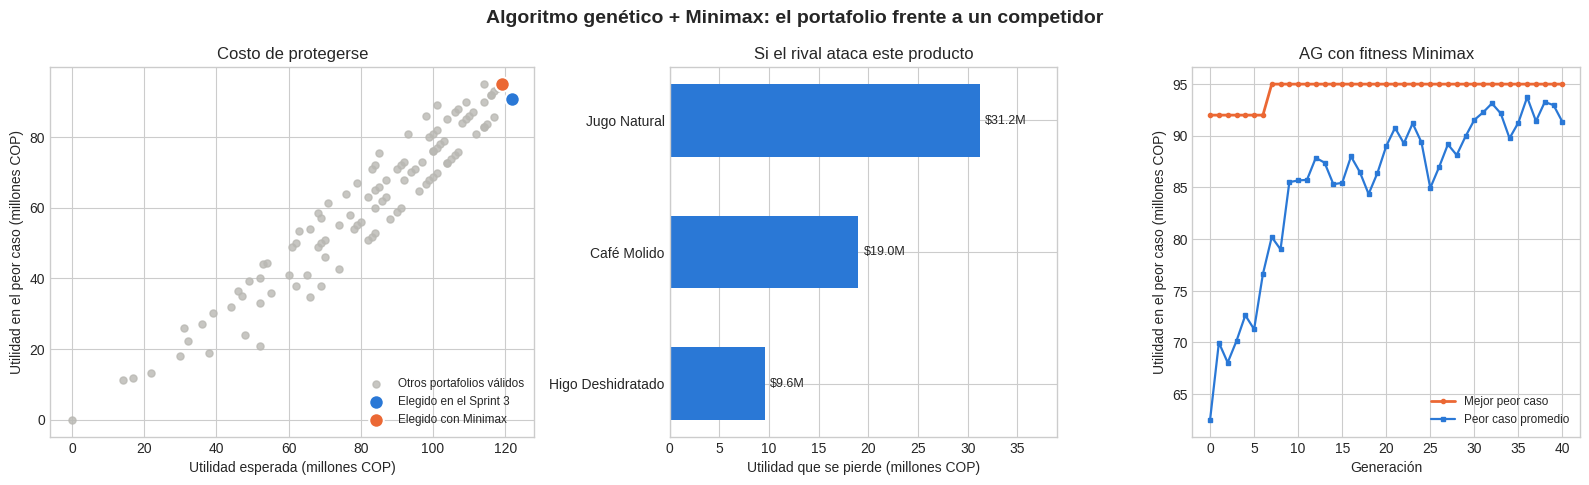

In [9]:
# @title
# CÓDIGO DE APOYO VISUAL (oculto)
# Panel 1: los portafolios válidos según utilidad esperada y peor caso.
# Panel 2: cuánto pierde el portafolio del Sprint 3 según el producto atacado.
# Panel 3: evolución del AG con fitness Minimax.
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#b9b8b3"
plt.style.use("seaborn-v0_8-whitegrid")

fig, ejes = plt.subplots(1, 3, figsize=(16, 4.9), gridspec_kw={"width_ratios": [1.25, 1, 1]})

ax = ejes[0]
ax.scatter([utilidad_total(c) / 1e6 for c in VALIDAS], [utilidad_peor_caso(c) / 1e6 for c in VALIDAS],
           s=26, color=GRIS, alpha=0.8, label="Otros portafolios válidos")
ax.scatter(utilidad_total(PORTAFOLIO_SPRINT3) / 1e6, utilidad_peor_caso(PORTAFOLIO_SPRINT3) / 1e6,
           s=110, color=AZUL, edgecolor="white", linewidth=1.5, zorder=3, label="Elegido en el Sprint 3")
ax.scatter(utilidad_total(mejor_minimax) / 1e6, utilidad_peor_caso(mejor_minimax) / 1e6,
           s=110, color=NARANJA, edgecolor="white", linewidth=1.5, zorder=3, label="Elegido con Minimax")
ax.set_xlabel("Utilidad esperada (millones COP)")
ax.set_ylabel("Utilidad en el peor caso (millones COP)")
ax.set_title("Costo de protegerse")
ax.legend(loc="lower right", fontsize=8.5)

ax = ejes[1]
perd = perdidas_por_ataque(PORTAFOLIO_SPRINT3)
orden = sorted(perd, key=perd.get)
ax.barh([corto(n) for n in orden], [perd[n] / 1e6 for n in orden], color=AZUL, height=0.55)
for y, n in enumerate(orden):
    ax.text(perd[n] / 1e6 + 0.5, y, f"${perd[n]/1e6:.1f}M", va="center", fontsize=9)
ax.set_xlim(0, max(perd.values()) / 1e6 * 1.25)
ax.set_xlabel("Utilidad que se pierde (millones COP)")
ax.set_title("Si el rival ataca este producto")

ax = ejes[2]
ax.plot(hist_minimax["Generación"], hist_minimax["Mejor peor caso"] / 1e6, marker="o", markersize=3, linewidth=2, color=NARANJA, label="Mejor peor caso")
ax.plot(hist_minimax["Generación"], hist_minimax["Peor caso promedio"] / 1e6, marker="s", markersize=3, linewidth=1.6, color=AZUL, label="Peor caso promedio")
ax.set_xlabel("Generación"); ax.set_ylabel("Utilidad en el peor caso (millones COP)")
ax.set_title("AG con fitness Minimax")
ax.legend(loc="lower right", fontsize=8.5)

fig.suptitle("Algoritmo genético + Minimax: el portafolio frente a un competidor", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## Parte 5 — Interpretación del resultado

**1. El juego de un solo producto (Jugo Natural).**
- **Caso A (erosión 35%):** el equilibrio de Nash es (Lanzar, Entrar) y Riovalle gana **3,8M** en vez de los 22M que muestra el Sprint 3. Esos 22M solo ocurren si el rival no existe.
- **Caso B (erosión 50%):** lanzar deja −4M, así que a Riovalle le conviene no lanzar el Jugo. Eso liberaría $30M de presupuesto y 10 posiciones de bodega.
- **Caso C (erosión 50%, pero entrar contra un producto ya lanzado le da pérdida al rival):** hay dos equilibrios. Como Riovalle mueve primero, lanzar funciona como compromiso y el rival no entra, con un resultado de **22M** para Riovalle.
- **Erosión de equilibrio:** Higo 43,8%, Jugo 42,3% y Café 42,1%. Con las erosiones supuestas, el Jugo (60%) y el Café (50%) pierden dinero el primer año si el rival entra en ellos. El Higo (30%) no.

**2. El portafolio del Sprint 3 frente a un rival.** Si el rival ataca el producto que más daño hace, ataca el Jugo y el portafolio de 122M queda en **90,8M** (pierde 31,2M). El riesgo está concentrado: el Jugo aporta 43% de la utilidad.

**3. El AG con *fitness* Minimax.** Escoge **Higo, Mix de Frutos Secos, Barra Energética y Snack de Plátano**: $119M de utilidad esperada y **95,0M en el peor caso**.

| Portafolio | Utilidad esperada | Peor caso |
|---|---|---|
| Sprint 3 (Higo, Jugo, Café) | $122,0M | $90,8M |
| Minimax (Higo, Mix, Barra, Snack) | $119,0M | $95,0M |

Se renuncian 3M de utilidad esperada a cambio de 4,2M más de protección. La fuerza bruta confirma que 95,0M es el máximo peor caso posible. Hay dos portafolios empatados en ese valor (el otro es Higo, Granola, Compota y Café, con 114M esperados) y el AG se queda con el de mayor utilidad esperada gracias al desempate. En 20 semillas distintas, el AG llegó al óptimo en 19 de 20 corridas con los dos criterios.

**4. Sensibilidad: depende de qué tan fuerte sea el rival.**

| Fuerza del rival (un ataque) | Peor caso óptimo | Peor caso del portafolio Sprint 3 | Diferencia |
|---|---|---|---|
| Erosión × 0,5 | $107,0M | $106,4M | $0,6M |
| Erosión × 1,0 | $95,0M | $90,8M | $4,2M |
| Erosión × 1,5 | $85,5M | $75,2M | $10,3M |

El portafolio del Sprint 3 nunca es el óptimo según Minimax, pero escogerlo cuesta casi nada si el rival es débil y cuesta bastante si es fuerte. Si el rival puede atacar dos productos a la vez (erosión × 1,0), la diferencia sube a $13,6M ($85,4M contra $71,8M).

**5. Cómo leer estos números.** No son un pronóstico, porque dependen de la erosión supuesta. Lo que sí se puede defender es la estructura: el portafolio que más rinde en promedio concentra el riesgo en un producto fácil de copiar, y el AG con Minimax lo reparte. La decisión final depende de cuánto riesgo está dispuesta a asumir MegaMarket y de qué tan fuerte es el competidor real.



- **La erosión y los pagos del rival son supuestos.** La erosión es el parámetro clave y se estima con datos reales: qué pasó cuando un competidor lanzó algo parecido, cuánto espacio tiene en góndola y a qué precio vende.
- **Minimax es pesimista por diseño.** Supone que el rival minimiza nuestra utilidad, cuando un competidor real maximiza la suya. Por eso se combina con la matriz de pagos (Parte 1), donde el rival sí tiene su propio pago.
- **Es un Minimax simplificado.** El del curso recorre árboles de varios niveles con poda Alfa-Beta. Aquí hay un solo movimiento del rival, así que se reduce a un máximo de pérdidas.
- **El análisis usa el primer año.** El costo de lanzamiento se paga una vez, así que desde el segundo año el umbral de equilibrio cambia.
- **Con 8 candidatos la fuerza bruta basta.** El valor del AG aquí es el método: sigue funcionando cuando los candidatos son decenas y revisar todas las combinaciones deja de ser posible.